In [1]:
print('helllo')

helllo


In [1]:
# import gemini
# from gemini import GeminiClient
from dotenv import load_dotenv
import os
load_dotenv()
from langgraph.graph import StateGraph, START, END
import operator
from typing import TypedDict, List, Annotated
from langchain.chat_models import init_chat_model
from pydantic import BaseModel, Field


In [3]:
# load env
os.environ['GOOGLE_API_KEY'] = os.getenv('GOOGLE_API_KEY')

In [4]:
from langchain_google_genai import ChatGoogleGenerativeAI
model = ChatGoogleGenerativeAI(model="gemini-2.5-flash")

c:\Langgraph_practice\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [8]:
response = model.invoke("who is the president of usa?")
print(response.content)

The current President of the United States is **Joe Biden**.

He took office on January 20, 2021.


In [10]:
class outputformat(BaseModel):
    name : str = Field(description="name of the person")
    age : int = Field(description="age of the person")
    DOB : str = Field(description="date of birth of the person")

structured_output = model.with_structured_output(outputformat)

In [11]:
def process_response(prompt:str) :
    response = structured_output.invoke(prompt)
    return response

prompt = "Tell me about Albert Einstein"
result = process_response(prompt)
print(result)

name='Albert Einstein' age=76 DOB='March 14, 1879'


In [38]:
class inputt(BaseModel):
    name : str
    age : int
    place : str

def process(data: inputt):
    name = data.name
    age = data.age
    place = data.place
    return f"{name} is {age} years old and lives in {place}"
data = inputt(name="John", age=30, place="New York")
output = process(data)
print(output)

John is 30 years old and lives in New York


In [23]:
class validateinput(BaseModel):
    name: str
    surname: str

class greet(TypedDict):
    name: str
    surname: str

def greeting(state:greet) -> greet:
    state["name"] = state['name'] + state['surname'], ", Welcome to langraph!"
    return state

In [26]:
graph = StateGraph(validateinput)
graph.add_node('greeting', greeting)

graph.add_edge(START, 'greeting')
graph.add_edge('greeting', END)

initial_state = {
    'name': 'Alice',
    'surname': 'Smith'
}

workflow = graph.compile()
result = workflow.invoke(initial_state)
print(result['name'])

    

('AliceSmith', ', Welcome to langraph!')


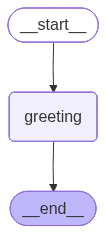

In [25]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())